In [1]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Dataset random sesuai modul
d = 128
nb = 100000
nq = 1000
k = 10
np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')
faiss.omp_set_num_threads(4)

# Ground truth dengan FAISS brute force
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
_, gt_idx = index_flat.search(xq, k)

def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

results = {'Annoy': [], 'Faiss': [], 'HNSW': []}
rows = []

In [2]:
# Index dibuat sekali karena yang diukur hanya waktu query.
index_annoy = AnnoyIndex(d, 'euclidean')
index_annoy.set_seed(42)
for i, v in enumerate(xb):
    index_annoy.add_item(i, v)
index_annoy.build(10, n_jobs=4)

def run_annoy(search_k=1000):
    start = time.perf_counter()
    I = [index_annoy.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.perf_counter() - start) * 1000 / len(xq)
    return recall_at_k(I, gt_idx, k), elapsed

for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(search_k=sk)
    results['Annoy'].append((rec, t))
    rows.append({'Model': 'Annoy', 'Parameter': f'search_k={sk}',
                 'Recall@10': rec, 'Waktu (ms/query)': t, 'QPS': 1000 / t})
del index_annoy

In [3]:
quantizer = faiss.IndexFlatL2(d)
index_faiss = faiss.IndexIVFFlat(quantizer, d, 100, faiss.METRIC_L2)
index_faiss.cp.seed = 42
index_faiss.train(xb)
index_faiss.add(xb)

def run_faiss(nprobe=10):
    index_faiss.nprobe = nprobe
    start = time.perf_counter()
    _, I = index_faiss.search(xq, k)
    elapsed = (time.perf_counter() - start) * 1000 / len(xq)
    return recall_at_k(I, gt_idx, k), elapsed

for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(nprobe=npb)
    results['Faiss'].append((rec, t))
    rows.append({'Model': 'Faiss', 'Parameter': f'nprobe={npb}',
                 'Recall@10': rec, 'Waktu (ms/query)': t, 'QPS': 1000 / t})
del index_faiss, quantizer

In [4]:
p = hnswlib.Index(space='l2', dim=d)
p.init_index(max_elements=len(xb), ef_construction=200, M=16, random_seed=42)
p.set_num_threads(4)
p.add_items(xb)

def run_hnsw(ef=100):
    p.set_ef(ef)
    start = time.perf_counter()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.perf_counter() - start) * 1000 / len(xq)
    return recall_at_k(I, gt_idx, k), elapsed

for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(ef=ef)
    results['HNSW'].append((rec, t))
    rows.append({'Model': 'HNSW', 'Parameter': f'ef={ef}',
                 'Recall@10': rec, 'Waktu (ms/query)': t, 'QPS': 1000 / t})
del p

,Model,Parameter,Recall@10,Waktu (ms/query),QPS
0,Annoy,search_k=200,0.0218,0.109368,9143.475764
1,Annoy,search_k=500,0.0445,0.169307,5906.440797
2,Annoy,search_k=1000,0.0752,0.308744,3238.926192
3,Annoy,search_k=2000,0.1300,0.542485,1843.369960
4,Faiss,nprobe=1,0.0522,0.017098,58485.004446
5,Faiss,nprobe=5,0.1980,0.068616,14573.924043
6,Faiss,nprobe=10,0.3238,0.154746,6462.215105
7,Faiss,nprobe=20,0.5074,0.284823,3510.947485
8,HNSW,ef=50,0.3003,0.074255,13467.106592
9,HNSW,ef=100,0.4435,0.144021,6943.431861


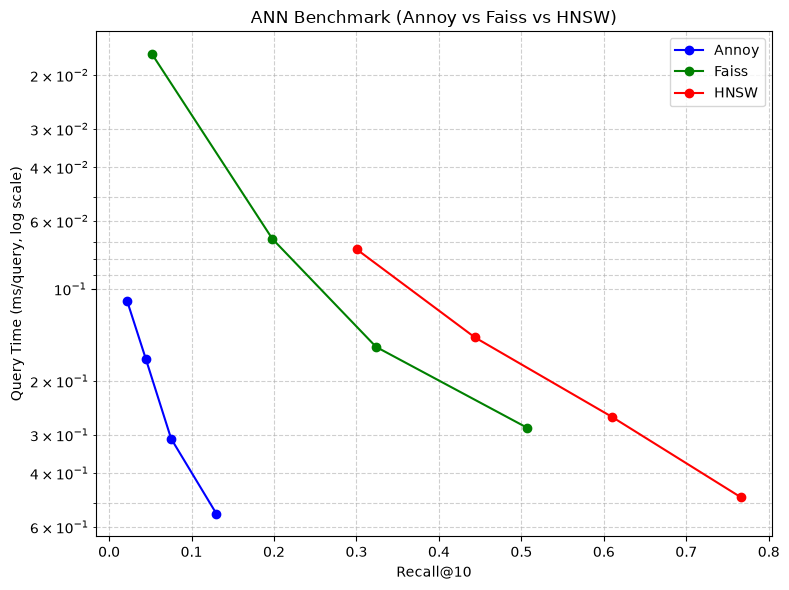

In [5]:
tabel_benchmark = pd.DataFrame(rows)
display(tabel_benchmark)

plt.figure(figsize=(8, 6))
for label, color in zip(results.keys(), ['blue', 'green', 'red']):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker='o', label=label, color=color)
plt.xlabel('Recall@10')
plt.ylabel('Query Time (ms/query, log scale)')
plt.yscale('log')
plt.gca().invert_yaxis()
plt.title('ANN Benchmark (Annoy vs Faiss vs HNSW)')
plt.legend()
plt.grid(True, which='both', ls='--', alpha=0.6)
plt.tight_layout()
plt.show()

Recall tertinggi pada percobaan ini adalah HNSW dengan ef=400, yaitu 0,7682. Parameter pencarian yang lebih besar meningkatkan recall, tetapi juga menambah waktu pencarian. Posisi kanan atas lebih baik karena sumbu waktu pada grafik dibalik. Annoy mencari per query, sedangkan FAISS dan HNSW memakai batch 4 thread, sehingga QPS mengikuti cara pemanggilan tersebut.